<a href="https://colab.research.google.com/github/uhar0562-dev/crop-production-prediction/blob/main/AI_MP5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv('/content/agri.csv')

In [5]:
df.head()

,State,District,Crop,Year,Season,Area,Area Units,Production,Production Units,Yield
0,Andaman and Nicobar Islands,NICOBARS,Arecanut,2001-02,Kharif,1254.0,Hectare,2061.0,Tonnes,1.643541
1,Andaman and Nicobar Islands,NICOBARS,Arecanut,2002-03,Whole Year,1258.0,Hectare,2083.0,Tonnes,1.655803
2,Andaman and Nicobar Islands,NICOBARS,Arecanut,2003-04,Whole Year,1261.0,Hectare,1525.0,Tonnes,1.209358
3,Andaman and Nicobar Islands,NORTH AND MIDDLE ANDAMAN,Arecanut,2001-02,Kharif,3100.0,Hectare,5239.0,Tonnes,1.690000
4,Andaman and Nicobar Islands,SOUTH ANDAMANS,Arecanut,2002-03,Whole Year,3105.0,Hectare,5267.0,Tonnes,1.696296


In [6]:
df.tail()

,State,District,Crop,Year,Season,Area,Area Units,Production,Production Units,Yield
345402,Manipur,IMPHAL WEST,NaN,2019-20,Rabi,NaN,Hectare,NaN,Tonnes,NaN
345403,Manipur,SENAPATI,NaN,2019-20,Rabi,NaN,Hectare,NaN,Tonnes,NaN
345404,Manipur,TAMENGLONG,NaN,2019-20,Rabi,NaN,Hectare,NaN,Tonnes,NaN
345405,Manipur,THOUBAL,NaN,2019-20,Rabi,NaN,Hectare,NaN,Tonnes,NaN
345406,Manipur,UKHRUL,NaN,2019-20,Rabi,NaN,Hectare,NaN,Tonnes,NaN


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 345407 entries, 0 to 345406
Data columns (total 10 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   State             345407 non-null  object 
 1   District          345407 non-null  object 
 2   Crop              345375 non-null  object 
 3   Year              345407 non-null  object 
 4   Season            345406 non-null  object 
 5   Area              345374 non-null  float64
 6   Area Units        345407 non-null  object 
 7   Production        340414 non-null  float64
 8   Production Units  345407 non-null  object 
 9   Yield             345374 non-null  float64
dtypes: float64(3), object(7)
memory usage: 26.4+ MB


In [8]:
df.describe()


,Area,Production,Yield
count,3.453740e+05,3.404140e+05,345374.000000
mean,1.167019e+04,9.583711e+05,79.407569
std,4.583843e+04,2.152986e+07,916.628744
min,4.000000e-03,0.000000e+00,0.000000
25%,7.400000e+01,8.700000e+01,0.546742
50%,5.320000e+02,7.170000e+02,1.000000
75%,4.110000e+03,7.176000e+03,2.467080
max,8.580100e+06,1.597800e+09,43958.333330


In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
#df.drop_duplicates(inplace=True)

In [13]:
df.columns

Index(['State', 'District', 'Crop', 'Year', 'Season', 'Area', 'Area Units',
       'Production', 'Production Units', 'Yield'],
      dtype='object')

In [16]:
df.shape

(345407, 10)

In [14]:
df.isnull().sum()

,0
State,0
District,0
Crop,32
Year,0
Season,1
Area,33
Area Units,0
Production,4993
Production Units,0
Yield,33


In [17]:
# Remove duplicate records
df = df.drop_duplicates()


In [18]:
# Remove extra spaces from column names
df.columns = df.columns.str.strip()

In [19]:
# Remove rows where production is missing
df = df.dropna(subset=['Production'])


In [20]:
# Remove invalid production values
df = df[df['Production'] >= 0]
# Fill missing categorical values
cat_cols = ['State', 'District', 'Crop', 'Year', 'Season']

In [21]:
for col in cat_cols:
    df[col] = df[col].fillna('Unknown').astype(str)

# Fill missing area values
df['Area'] = df['Area'].fillna(df['Area'].median())

print("Missing values after cleaning:")
print(df.isnull().sum())

print("Final dataset shape:", df.shape)

Missing values after cleaning:
State               0
District            0
Crop                0
Year                0
Season              0
Area                0
Area Units          0
Production          0
Production Units    0
Yield               0
dtype: int64
Final dataset shape: (340414, 10)


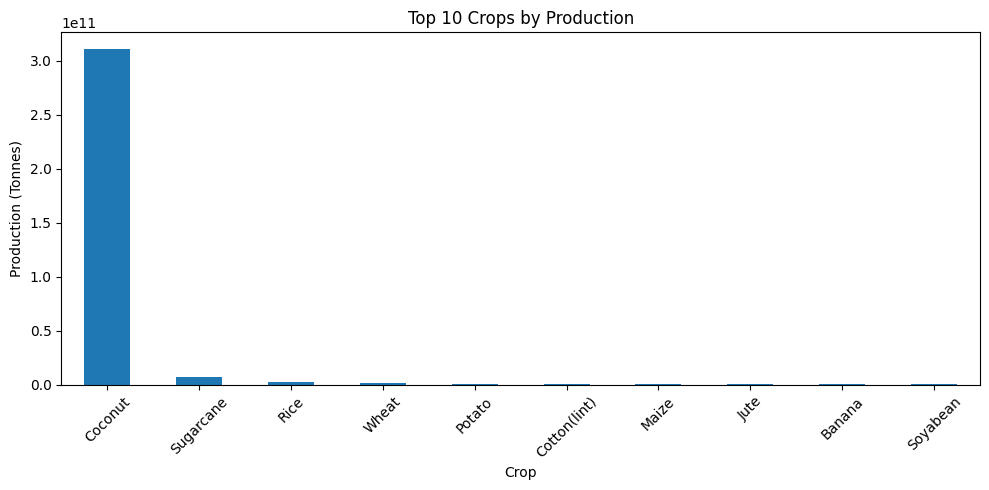

In [22]:
# 1. Top 10 crops by production
top_crops = (
    df.groupby('Crop')['Production']
    .sum()
    .nlargest(10)
)

plt.figure(figsize=(10,5))
top_crops.plot(kind='bar')
plt.title('Top 10 Crops by Production')
plt.xlabel('Crop')
plt.ylabel('Production (Tonnes)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

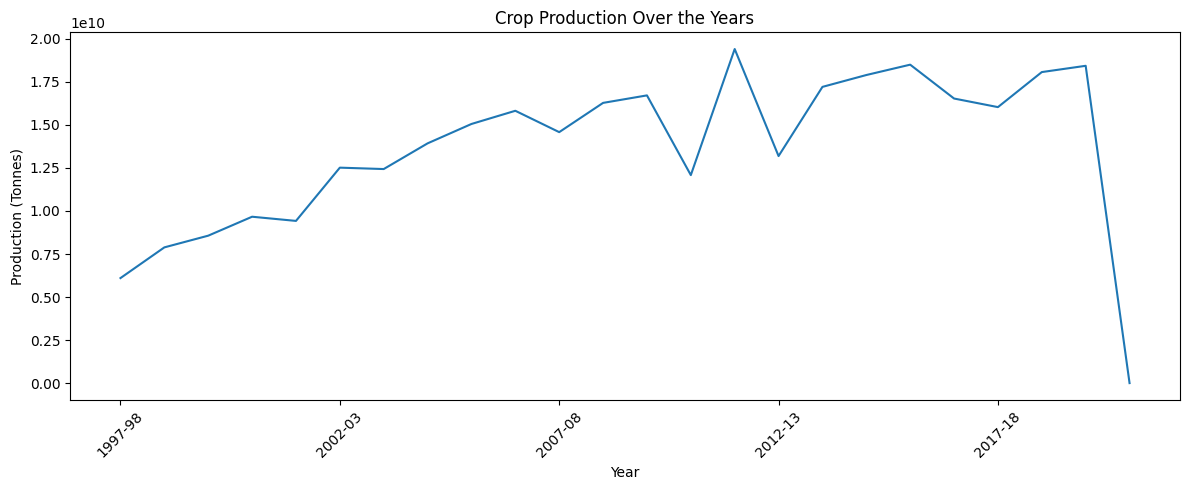

In [23]:
# 2. Production by year
year_data = df.groupby('Year')['Production'].sum()

plt.figure(figsize=(12,5))
year_data.plot()
plt.title('Crop Production Over the Years')
plt.xlabel('Year')
plt.ylabel('Production (Tonnes)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

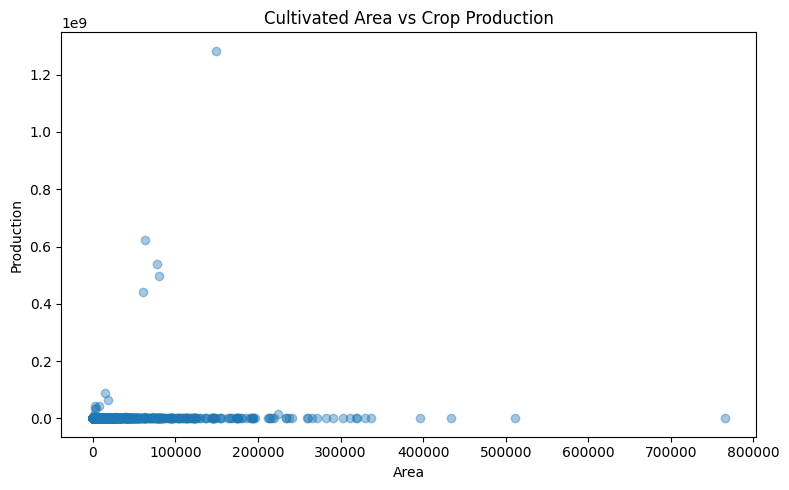

In [24]:
# 3. Area vs Production
sample = df.sample(min(3000, len(df)), random_state=42)

plt.figure(figsize=(8,5))
plt.scatter(sample['Area'], sample['Production'], alpha=0.4)
plt.title('Cultivated Area vs Crop Production')
plt.xlabel('Area')
plt.ylabel('Production')
plt.tight_layout()
plt.show()

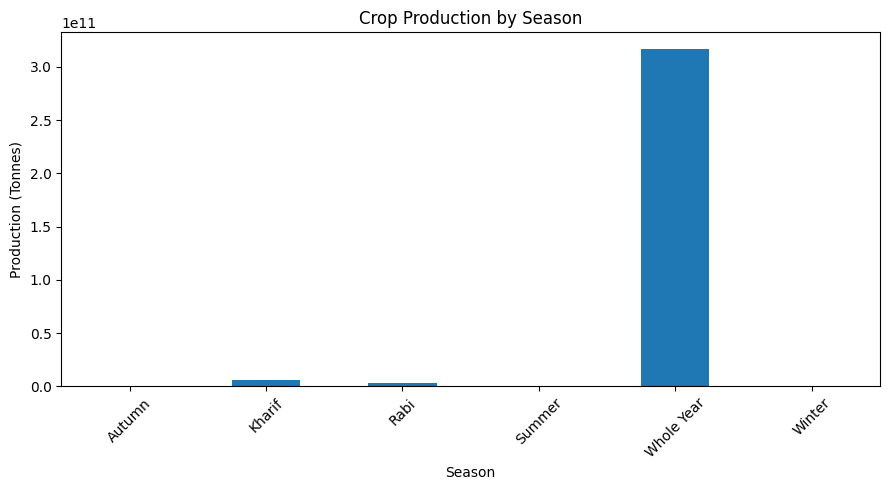

In [25]:
# 4. Production by season
season_data = df.groupby('Season')['Production'].sum()

plt.figure(figsize=(9,5))
season_data.plot(kind='bar')
plt.title('Crop Production by Season')
plt.xlabel('Season')
plt.ylabel('Production (Tonnes)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [26]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score

# Input features
X = df[['State', 'District', 'Crop',
        'Year', 'Season', 'Area']]

# Target variable
y = df['Production']

categorical = ['State', 'District', 'Crop',
               'Year', 'Season']

numerical = ['Area']

preprocessor = ColumnTransformer([
    ('cat', OrdinalEncoder(
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ), categorical),

    ('num', SimpleImputer(strategy='median'), numerical)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (272331, 6)
Testing data: (68083, 6)


In [27]:
model = Pipeline([
    ('preprocessing', preprocessor),
    ('regressor', HistGradientBoostingRegressor(
        max_iter=150,
        learning_rate=0.1,
        max_leaf_nodes=31,
        random_state=42
    ))
])

# Train model using log-transformed production
model.fit(X_train, np.log1p(y_train))

print("Model training completed!")

Model training completed!


In [28]:
predictions = np.expm1(model.predict(X_test))

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 427376.3217865424
RMSE: 12296619.391313003
R2 Score: 0.7103293128275799


In [29]:
new_data = pd.DataFrame({
    'State': ['Karnataka'],
    'District': ['Bangalore Rural'],
    'Crop': ['Rice'],
    'Year': ['2020'],
    'Season': ['Kharif'],
    'Area': [1000]
})

predicted_production = np.expm1(
    model.predict(new_data)
)

print(
    "Expected Crop Production:",
    round(predicted_production[0], 2),
    "Tonnes"
)

Expected Crop Production: 1317.37 Tonnes
